# 03 // Host (human) read removal

This notebook:
- Removes reads that come from the human host
- Keeps track of how many read pairs every sample loses.

We use [Bowtie2](https://github.com/BenLangmead/bowtie2) through the QIIME 2 plugin `q2-quality-control` (`qiime quality-control filter-reads`).

The human reference: GRCh38 + draft human pangenome. The pangenome of the Human Pangenome Reference Consortium contains genomes of people from many populations, including people of African ancestry, which is very relevant for our group and it should identify human reads that differ from the single GRCh38 reference.

As alignment mode, the default "local" is kept where a read counts as human if only a part of it aligns. A pair is removed if either read aligns to the human reference. Pairs where neither read looks human are kept. 

NOTE The Madagascar and Guinea-Bissau reads already seemed pre-processed (explained in notebook 01). We still run the same steps on every sample.

**Inputs:** the quality-controlled reads from notebook 02 (QIIME 2 cache, keys `qc_reads_<batch>`), and `results/02_sample_overview.tsv`.

**Outputs:**
- host-free reads in the QIIME 2 cache in scratch (keys `hostfree_reads_<batch>`), used by notebook 04 and for functional annotation
- `results/03_sample_overview.tsv`: the overview from notebook 02 plus the read pairs after host removal
- `results/03_host_reads_per_sample.png`

## Setup

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Work from the repository root (this notebook is one level inside it, in notebooks/)
if Path.cwd().name == "notebooks":
    os.chdir("..")
print("Working directory:", Path.cwd())

# This makes qiime available to "!" shell commands
env_bin = str(Path(sys.executable).parent)
os.environ["PATH"] = env_bin + os.pathsep + os.environ["PATH"]

# Small outputs go to results/, large outputs stay in scratch:
RESULTS = Path("results")
SCRATCH = Path("/cluster/scratch") / os.environ["USER"] / "africangut"
CACHE = SCRATCH / "qiime_cache"           
HOST_DIR = SCRATCH / "03_host_removal"     # one folder per batch, with the read counts

# Urbanization levels:
URBANIZATION_ORDER = ["Urban", "Peri-urban", "Peri-rural", "Hinterland"]
COLOURS = {"Urban": "#2a78d6", "Peri-urban": "#eb6834", "Peri-rural": "#1baf7a", "Hinterland": "#eda100"}
PLOT_LABELS = {"Hinterland": "Rural"}   # in plots, "Hinterland" is labelled "Rural"

# Plot style:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# Sample overview from notebook 02 (raw and quality-controlled read pairs per sample)
overview = pd.read_csv(RESULTS / "02_sample_overview.tsv", sep="\t", index_col="sample_id")
overview["urbanization"] = pd.Categorical(overview["urbanization"], categories=URBANIZATION_ORDER)
BATCHES = sorted(overview["batch"].unique())
print("Batches:", BATCHES)

Working directory: /cluster/home/mozdemir/microbiomes
Batches: ['CMR_126', 'GNB_101', 'GNB_151', 'MDG_101', 'TZA_151']


## 1. Building the human reference index (run once)

Submitting below script downloads GRCh38 (NCBI) and the draft human pangenome (EBI), combines them into one reference and builds the index needed by Bowtie2, which is stored in the QIIME 2 cache. Can take a few hours!

In [11]:
!cat scripts/03_build_human_index.sh

#!/bin/bash
#SBATCH --job-name=03_build_human_index
#SBATCH --account=public
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=16
#SBATCH --mem-per-cpu=6G
#SBATCH --time=48:00:00
#SBATCH --output=logs/%x_%j.out
#SBATCH --error=logs/%x_%j.err

# Building the Bowtie2 index of the human reference and storing it in the QIIME 2 cache.
# Used by notebooks/03_host_removal.ipynb

set -euo pipefail

CACHE="/cluster/scratch/$USER/africangut/qiime_cache"

# Temporary files (downloads, combined FASTA) in scratch, deleted when the job ends
export TMPDIR="/cluster/scratch/$USER/africangut/tmp/$SLURM_JOB_ID"
mkdir -p "$TMPDIR"
trap 'rm -rf "$TMPDIR"' EXIT

# Internet access through the ETH proxy, and the course environment
set +eu
source ~/.bashrc
module load eth_proxy
conda activate rachis-moshpit-2026.7
set -eu

# Downloading both references (details in notebook),
# combining them and building the Bowtie2 index 
qiime quality-control construct-human-pangenome-index \
    --p-threads 16 \
    --o-index "$C

In [13]:
# Submitting the index job, unless the cache already holds the index
if (CACHE / "keys" / "human_pangenome_index").exists():
    print("The human reference index is already in the cache.")
else:
    !sbatch scripts/03_build_human_index.sh

The human reference index is already in the cache.


In [14]:
# Checking my queue
!squeue --me

             JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)


## 2. Test run on three samples

The host-removal job for one batch: aligning the quality-controlled read pairs to the human reference (Bowtie2), only the pairs in which neither read aligns will be kept and `demux summarize` will count the read pairs left (per sample). 

First we run it on the three test samples from notebook 02, as a check. 

In [10]:
!cat scripts/03_host_removal.sh

#!/bin/bash
#SBATCH --job-name=03_host_removal
#SBATCH --account=public
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=8
#SBATCH --mem-per-cpu=12G
#SBATCH --time=48:00:00
#SBATCH --output=logs/%x_%j.out
#SBATCH --error=logs/%x_%j.err

# Removes human (host) reads from one batch of quality-controlled reads with Bowtie2.
# Used by notebooks/03_host_removal.ipynb (after scripts/03_build_human_index.sh is run)

set -euo pipefail

BATCH="$1"
CACHE="/cluster/scratch/$USER/africangut/qiime_cache"
OUT_DIR="/cluster/scratch/$USER/africangut/03_host_removal/$BATCH"
mkdir -p "$OUT_DIR"
echo "Batch: $BATCH"

# Temporary files (Bowtie2 alignments) in scratch, deleted when the job ends
export TMPDIR="/cluster/scratch/$USER/africangut/tmp/$SLURM_JOB_ID"
mkdir -p "$TMPDIR"
trap 'rm -rf "$TMPDIR"' EXIT

# Activating the course environment 
set +eu; source ~/.bashrc; conda activate rachis-moshpit-2026.7; set -eu

# 1) Align the read pairs to the human reference and keep only the pairs in which
#    neither 

In [2]:
# Submit the test job, unless it has run already
if (HOST_DIR / "test" / "hostfree_reads_summary").exists():
    print("The test has run already.")
else:
    !sbatch --job-name=03_host_removal_test scripts/03_host_removal.sh test

The test has run already.


In [6]:
!squeue --me

             JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)


After the run is finished we read the counts. The helper function below returns the read pairs left per sample for one batch (similar to notebook 01, the forward-read count = the number of read pairs).

In [3]:
def read_hostfree_counts(batch):
    # Read pairs per sample after host removal, from the demux summarize table of one batch
    counts_file = HOST_DIR / batch / "hostfree_reads_summary" / "per-sample-fastq-counts.tsv"
    counts = pd.read_csv(counts_file, sep="\t", index_col=0)
    counts.columns = ["forward_reads", "reverse_reads"]
    return counts["forward_reads"]


# Comparing the read pairs before (after quality control) and after host removal
test_counts = read_hostfree_counts("test")
test = overview.loc[test_counts.index, ["batch", "qc_read_pairs"]].copy()
test["hostfree_read_pairs"] = test_counts
test["pct_host"] = 100 * (test["qc_read_pairs"] - test["hostfree_read_pairs"]) / test["qc_read_pairs"]
test.round(2)

,batch,qc_read_pairs,hostfree_read_pairs,pct_host
sample ID,,,,
SRR13348807,TZA_151,11138174,11130557,0.07
SRR7658613,MDG_101,3113971,3113897,0.00
SRR9293007,CMR_126,7718695,7718224,0.01


## 3. Running all batches

Submitting one job per batch to run in parallel. Warning: the largest batch (Madagascar, about 420 million read pairs) takes almost a day!

In [4]:
# Submit one job per batch, skipping batches that have run already
for batch in BATCHES:
    if (HOST_DIR / batch / "hostfree_reads_summary").exists():
        print(batch, "has run already")
    else:
        !sbatch --job-name=03_host_removal_{batch} scripts/03_host_removal.sh {batch}

CMR_126 has run already
GNB_101 has run already
GNB_151 has run already
MDG_101 has run already
TZA_151 has run already


In [5]:
!squeue --me

/bin/bash: line 1: squeue: command not found


## 4. Human read pairs per sample

This adds the next column to the read-tracking table. As before, we flag but do not remove samples: in this case samples where more than 10% of the read pairs were human are flagged, and samples left with fewer than 5 million read pairs, as in notebook 01.

In [6]:
# Host-free read pairs of all batches in one table
hostfree = pd.concat([read_hostfree_counts(batch) for batch in BATCHES])
overview["hostfree_read_pairs"] = hostfree

# % of the quality-controlled read pairs that were human, and % of the raw read pairs left overall
overview["pct_host"] = 100 * (overview["qc_read_pairs"] - overview["hostfree_read_pairs"]) / overview["qc_read_pairs"]
overview["pct_retained_total"] = 100 * overview["hostfree_read_pairs"] / overview["raw_read_pairs"]

# Samples that get "flagged" (not removed): many human reads, or few read pairs left
HOST_FLAG = 10              # % human read pairs
LOW_DEPTH = 5_000_000       # read pairs left
overview["high_host"] = overview["pct_host"] > HOST_FLAG
overview["low_depth_hostfree"] = overview["hostfree_read_pairs"] < LOW_DEPTH

overview["pct_host"].describe().round(2)

count    53.00
mean      0.18
std       1.14
min       0.00
25%       0.00
50%       0.01
75%       0.01
max       8.35
Name: pct_host, dtype: float64

In [7]:
# Average % human read pairs per batch 
overview.groupby("batch")["pct_host"].agg(["mean", "min", "max"]).round(2)

,mean,min,max
batch,,,
CMR_126,0.03,0.01,0.18
GNB_101,0.00,0.00,0.00
GNB_151,0.01,0.01,0.01
MDG_101,0.00,0.00,0.00
TZA_151,1.12,0.04,8.35


In [8]:
# Flagged samples
overview[overview["high_host"] | overview["low_depth_hostfree"]][
    ["batch", "qc_read_pairs", "hostfree_read_pairs", "pct_host"]]

,batch,qc_read_pairs,hostfree_read_pairs,pct_host
sample_id,,,,
SRR7658613,MDG_101,3113971,3113897,0.002376


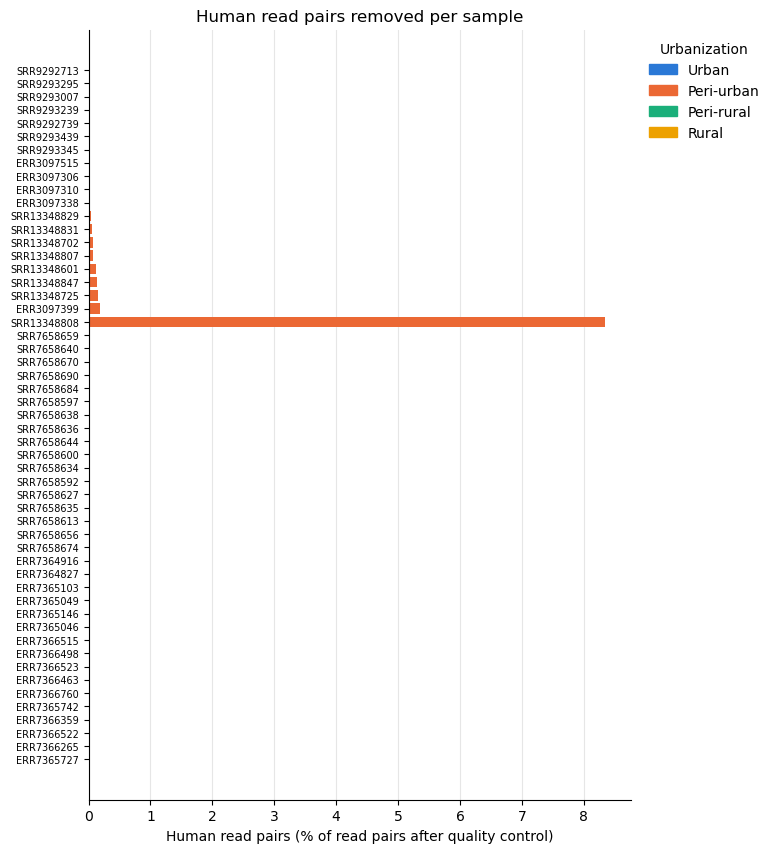

In [9]:
# Bar chart: % human read pairs per sample, grouped and coloured by urbanization level
plot_data = overview.sort_values(["urbanization", "pct_host"])
bar_colours = [COLOURS[level] for level in plot_data["urbanization"]]

fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(plot_data.index, plot_data["pct_host"], color=bar_colours, height=0.8)
ax.invert_yaxis()                                     # first level at the top
ax.set_xlabel("Human read pairs (% of read pairs after quality control)")
ax.set_title("Human read pairs removed per sample")
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="x", color="0.9")
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=c, label=PLOT_LABELS.get(level, level)) for level, c in COLOURS.items()],
          title="Urbanization", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

fig.savefig(RESULTS / "03_host_reads_per_sample.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Saving the sample overview

The overview from notebook 02 + the read pairs after host removal, the % human, the % of raw read pairs left overall, and the two flags.

In [10]:
overview.to_csv(RESULTS / "03_sample_overview.tsv", sep="\t", index_label="sample_id")
overview.head()

,country_iso3,urbanization,read_length,raw_read_pairs,low_depth,batch,qc_read_pairs,pct_retained_qc,low_retention_qc,hostfree_read_pairs,pct_host,pct_retained_total,high_host,low_depth_hostfree
sample_id,,,,,,,,,,,,,,
ERR3097306,CMR,Urban,126,8937217,False,CMR_126,8648650,96.771176,False,8647072,0.018246,96.753520,False,False
SRR9292713,CMR,Urban,126,10252447,False,CMR_126,10090796,98.423293,False,10090288,0.005034,98.418339,False,False
SRR9293345,CMR,Urban,126,8923296,False,CMR_126,8712245,97.634831,False,8711158,0.012477,97.622650,False,False
SRR9292739,CMR,Urban,126,9012176,False,CMR_126,8892146,98.668135,False,8891463,0.007681,98.660557,False,False
SRR9293007,CMR,Urban,126,7825668,False,CMR_126,7718695,98.633050,False,7718224,0.006102,98.627031,False,False
